# Clock Tree Synthesis: heurísticas H1, H2 e H3 com DME-Embed

Este notebook executa as heurísticas propostas no pré-projeto (**H1** BSG-DME, **H2** GRASP-CTS, **H3** ILS/SA-CTS) e testa as três hipóteses. As implementações estão em `cts_heuristicas.py`.

**Estado atual**
- Instâncias **sintéticas** (uniforme e clusterizada). O benchmark ISPD 2009/2010 será ligado depois: basta construir objetos `InstanciaCTS` (posições, cargas e fonte) a partir dos arquivos do concurso.
- As heurísticas de controle **C1, C2 e C3 ainda não estão implementadas** (só as assinaturas em `cts_heuristicas.py`). O notebook as detecta sozinho: enquanto não existirem, as Hipóteses 1 e 2 ficam **PENDENTES** (não refutadas), e a Hipótese 3 já roda, pois só depende de H1, H2 e H3.

**Roteiro:** 1. configuração → 2. instâncias → 3. demonstração em uma instância → 4. experimento → 5. tabelas → 6–8. hipóteses → 9. resumo.

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import src.cts_heuristicas as cts

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)

# --- Configuração -----------------------------------------------------------
# "teste": rápido, para validar o notebook. "completo": o protocolo do pré-projeto
# (n ∈ {100,...,10000}, 10 instâncias por combinação, R = 20 sementes).
PRESETS = {
    "teste":    dict(tamanhos=[100, 500],                   n_instancias=3,  R=3,  tempo_por_sink=0.01, tempo_minimo=2.0),
    "completo": dict(tamanhos=[100, 500, 1000, 5000, 10000], n_instancias=10, R=20, tempo_por_sink=0.02, tempo_minimo=5.0),
}
PRESET = "teste"
CFG = PRESETS[PRESET]

PERCENTUAL_SKEW = 0.05          # δ = 5% do atraso médio raiz-sink (referência C2 sem restrição de skew)
SEMENTE_INSTANCIAS = 2024
N_PROCESSOS = 1                 # > 1 paraleliza as execuções (H2 e H3 usam tempo real: mantenha núcleos livres)
ARQUIVO_CACHE = f"cache_cts_{PRESET}.pkl"   # permite retomar o experimento
PARAMS = {}                     # sobrescreve cts.PARAMS_PADRAO, ex.: {"k_rcl": 5, "alpha": 0.5}
                                # parâmetros dos controles: {"C1": {...}, "C2": {...}}

horas = cts.estimar_tempo_total(CFG["tamanhos"], CFG["n_instancias"], CFG["R"],
                                CFG["tempo_por_sink"], CFG["tempo_minimo"], n_processos=N_PROCESSOS)
print(f"Preset '{PRESET}': {CFG}")
print(f"Tempo estimado só de H2 + H3: {horas:.2f} h")
print("Controles implementados:", {c: cts.controle_disponivel(c) for c in cts.CONTROLES})
print("Parâmetros padrão:", cts.PARAMS_PADRAO)

Preset 'teste': {'tamanhos': [100, 500], 'n_instancias': 3, 'R': 3, 'tempo_por_sink': 0.01, 'tempo_minimo': 2.0}
Tempo estimado só de H2 + H3: 0.07 h
Controles implementados: {'C1': False, 'C2': False, 'C3': False}
Parâmetros padrão: {'k_rcl': 3, 'alpha': 0.3, 'k_viz': 6, 'vizinhos_busca': 6, 'raio_arvore': 3, 'incluir_folhas': False, 'theta0_rel': 0.001, 'theta_final_rel': 0.01, 'taxa_resfriamento': None, 'frac_fragmento': (0.02, 0.1), 'max_fusoes': 200, 'busca_focada': True, 'max_foco': 64, 'max_passadas_foco': 2}


## 1. Instâncias sintéticas

Chip quadrado de 10 000 µm de lado, fonte de clock no centro. Distribuição **uniforme** e **clusterizada** (mistura de 8 gaussianas com pesos assimétricos).

(100, clusterizada)    3
(100, uniforme)        3
(500, clusterizada)    3
(500, uniforme)        3
Name: count, dtype: int64


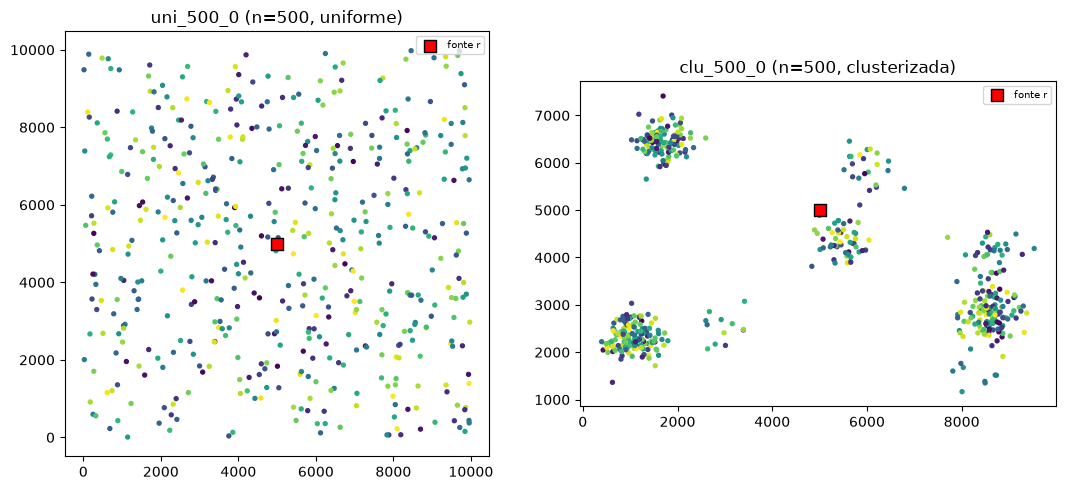

In [4]:
INSTANCIAS = cts.gerar_conjunto_sintetico(
    tamanhos=CFG["tamanhos"], distribuicoes=("uniforme", "clusterizada"),
    n_instancias=CFG["n_instancias"], semente_base=SEMENTE_INSTANCIAS)

print(pd.Series([(i.n, i.distribuicao) for i in INSTANCIAS]).value_counts().sort_index())

n_ex = min(500, max(CFG["tamanhos"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, d in zip(axes, ("uniforme", "clusterizada")):
    ex = next(i for i in INSTANCIAS if i.distribuicao == d and i.n == n_ex)
    cts.plotar_instancia(ex, ax=ax)
plt.tight_layout()
plt.show()

## 2. Demonstração em uma instância

Roda H1, H2 e H3 na mesma instância pequena, valida as árvores (sinks conectados, fio realizável, skew ≤ δ, consistência da avaliação incremental com o DME-Embed completo) e desenha as topologias embutidas.

Enquanto C2 não existir, δ é calibrado de forma **provisória** com uma árvore H1 sem restrição de skew (aparece um aviso). O `calibrar_delta` passa a usar a C2 sozinho quando ela for implementada.

/tmp/ipykernel_3591/995636331.py:2: UserWarning: C2 não implementada: δ calibrado provisoriamente com H1 (δ=∞). Recalibre quando C2 existir.
  delta_demo = cts.calibrar_delta(inst_demo, PERCENTUAL_SKEW)


,heuristica,WL,skew,delta,iteracoes,tempo_melhor_s
0,H1,137314.84,23.78,469.01,1,0.00
1,H2,123559.47,469.01,469.01,182,0.70
2,H3,122021.53,469.01,469.01,3727,2.28


,sinks_conectados,fio_realizavel,skew,skew_ok,wl,wl_consistente,skew_consistente,snaking_total
H1,True,True,23.778146,True,137314.839577,True,True,0.0
H2,True,True,469.006449,True,123559.469387,True,True,174.014637
H3,True,True,469.006449,True,122021.534768,True,True,914.807659


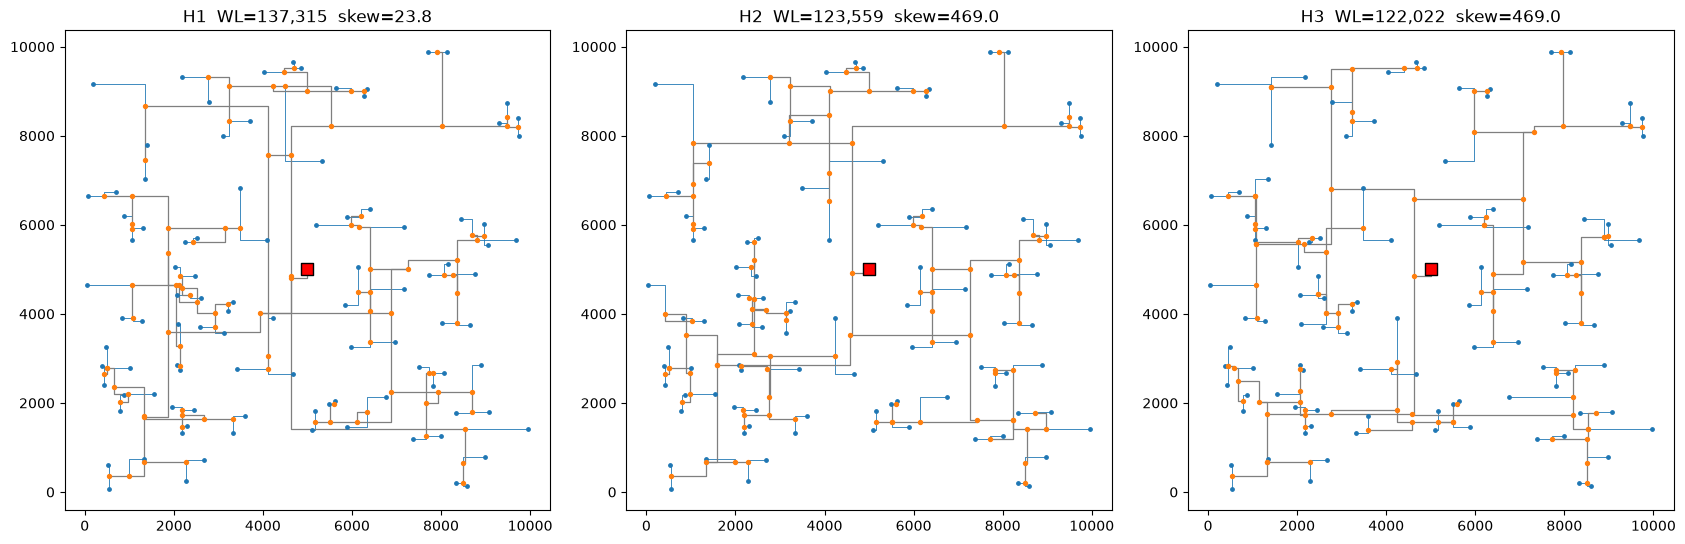

In [5]:
inst_demo = next(i for i in INSTANCIAS if i.distribuicao == "uniforme" and i.n == CFG["tamanhos"][0])
delta_demo = cts.calibrar_delta(inst_demo, PERCENTUAL_SKEW)
T_DEMO = 3.0   # segundos para H2 e H3

arv1, h1 = cts.heuristica_h1(inst_demo, delta_demo, semente=0)
arv2, h2 = cts.heuristica_h2(inst_demo, delta_demo, T_DEMO, semente=0)
arv3, h3 = cts.heuristica_h3(inst_demo, delta_demo, T_DEMO, semente=0)

demo = pd.DataFrame([
    dict(heuristica=h.nome, WL=h.wl, skew=h.skew, delta=delta_demo, iteracoes=h.n_iteracoes,
         tempo_melhor_s=h.tempo_melhor) for h in (h1, h2, h3)]).round(2)
display(demo)

verif = pd.DataFrame({h.nome: cts.verificar_arvore(a) for h, a in ((h1, arv1), (h2, arv2), (h3, arv3))}).T
display(verif)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, (nome, a) in zip(axes, (("H1", arv1), ("H2", arv2), ("H3", arv3))):
    cts.plotar_arvore(a, ax=ax, titulo=nome)
plt.tight_layout()
plt.show()

## 3. Experimento principal

Todas as heurísticas disponíveis são executadas em todas as instâncias, com o mesmo δ por instância. H1, H2 e H3 são estocásticas (R sementes); H2 e H3 têm o mesmo orçamento de tempo, proporcional a n. Controles não implementados são ignorados.

O resultado é salvo em `ARQUIVO_CACHE` e o experimento **retoma de onde parou** se for interrompido.

> **Atenção ao implementar C1–C3:** o δ de cada instância é calibrado uma vez, pela C2 (ou pelo substituto provisório). Depois de implementá-las, **apague o arquivo de cache** e rode de novo, para que todas as heurísticas usem o mesmo δ.

In [6]:
df, historicos, deltas = cts.executar_experimento(
    INSTANCIAS,
    percentual_skew=PERCENTUAL_SKEW,
    R=CFG["R"],
    tempo_por_sink=CFG["tempo_por_sink"],
    tempo_minimo=CFG["tempo_minimo"],
    params=PARAMS or None,
    arquivo_cache=ARQUIVO_CACHE,
    n_processos=N_PROCESSOS,
)
print(df.groupby(["heuristica"]).size().rename("execuções"))
df.head()

[aviso] C1 não implementada: ignorada neste experimento.
[aviso] C2 não implementada: ignorada neste experimento.
[aviso] C3 não implementada: ignorada neste experimento.


CTS:   0%|          | 0/108 [00:00<?, ?it/s]

heuristica
H1    36
H2    36
H3    36
Name: execuções, dtype: int64


,instancia,n,distribuicao,heuristica,semente,delta,wl,skew,viavel,tempo_s,tempo_melhor_s,n_iter
0,uni_100_0,100,uniforme,H1,1000,469.006449,133196.641912,66.493036,True,0.002756,0.002756,1
1,uni_100_0,100,uniforme,H1,1001,469.006449,134404.348114,469.006449,True,0.002913,0.002913,1
2,uni_100_0,100,uniforme,H1,1002,469.006449,138494.289497,469.006449,True,0.003140,0.003140,1
3,uni_100_0,100,uniforme,H2,1000,469.006449,123750.212056,469.006449,True,2.000007,1.474386,135
4,uni_100_0,100,uniforme,H2,1001,469.006449,123223.100641,469.006449,True,2.000311,0.658773,139


## 4. Resultados gerais

Tabela no formato do pré-projeto [Instância, n, Heurística, WL (µm), Skew, Tempo (s), Gap (%)]. WL e Gap são médias sobre as sementes; "Tempo" é o instante em que a melhor solução foi encontrada. O Gap é relativo à melhor solução da instância entre todas as heurísticas e execuções **disponíveis**.

In [7]:
tabela_geral = cts.tabela_resultados(df)
display(tabela_geral.head(30))
print("Resumo por n e heurística:")
display(cts.resumir_resultados(df))

,Instância,n,Heurística,WL (µm),Skew,Tempo (s),Gap (%)
0,uni_100_0,100,H1,135365.093,469.006,0.003,11.266
1,uni_100_0,100,H2,123399.773,469.006,1.367,1.431
2,uni_100_0,100,H3,122436.516,469.006,1.947,0.639
3,uni_100_1,100,H1,128550.288,494.138,0.003,9.587
4,uni_100_1,100,H2,119648.549,494.138,1.707,1.999
5,uni_100_1,100,H3,118054.868,494.138,1.567,0.640
6,uni_100_2,100,H1,129992.930,461.473,0.003,13.429
7,uni_100_2,100,H2,117803.390,461.473,1.470,2.793
8,uni_100_2,100,H3,115121.971,461.473,1.556,0.453
9,clu_100_0,100,H1,57745.591,325.628,0.003,22.142


Resumo por n e heurística:


wl_medio      wl_dp  gap_medio_pct  skew_max  taxa_viavel  tempo_melhor_s
n   heuristica                                                                             
100 H1           94018.455  37419.533         15.894   494.138          1.0           0.003
    H2           84103.900  36219.674          1.872   494.138          1.0           1.218
    H3           82949.167  35656.013          0.527   494.138          1.0           1.783
500 H1          217581.326  97212.296         16.955   487.206          1.0           0.020
    H2          192562.858  94744.901          0.515   487.206          1.0           2.335
    H3          195377.617  94257.766          2.623   487.206          1.0           4.793

## 5. Hipótese 1: qualidade frente aos baselines clássicos (n ≤ 5000)

**Confirmada** se pelo menos duas heurísticas propostas têm WL médio estatisticamente menor (Wilcoxon signed-rank unilateral, pareado por instância, p < 0,05) que pelo menos dois controles, com 100% das soluções das propostas satisfazendo skew ≤ δ.

Cada instância entra no teste com o WL médio sobre as sementes. Se menos de dois controles estiverem implementados, o veredito é **PENDENTE**.

Hipótese 1: PENDENTE  (pendente: requer ≥ 2 controles implementados (disponíveis: []))
Soluções das propostas com skew ≤ δ em 100%: True
Controles com skew ≤ δ em 100%: {}


""


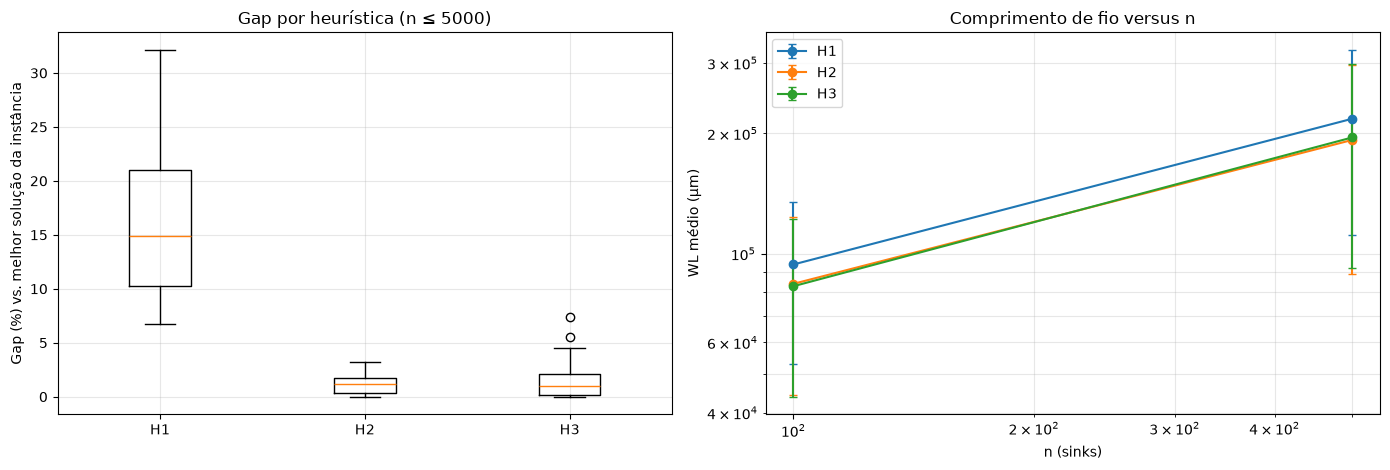

,Instância,n,Heurística,WL (µm),Skew,Tempo (s),Gap (%)
0,uni_100_0,100,H1,135365.093,469.006,0.003,11.266
1,uni_100_0,100,H2,123399.773,469.006,1.367,1.431
2,uni_100_0,100,H3,122436.516,469.006,1.947,0.639
3,uni_100_1,100,H1,128550.288,494.138,0.003,9.587
4,uni_100_1,100,H2,119648.549,494.138,1.707,1.999
5,uni_100_1,100,H3,118054.868,494.138,1.567,0.640
6,uni_100_2,100,H1,129992.930,461.473,0.003,13.429
7,uni_100_2,100,H2,117803.390,461.473,1.470,2.793
8,uni_100_2,100,H3,115121.971,461.473,1.556,0.453
9,clu_100_0,100,H1,57745.591,325.628,0.003,22.142


In [8]:
res1 = cts.testar_hipotese_1(df, n_max=5000, nivel=0.05)
cts.imprimir_veredito("Hipótese 1", res1)
print("Soluções das propostas com skew ≤ δ em 100%:", res1["skew_ok"])
print("Controles com skew ≤ δ em 100%:", res1["skew_controles_ok"])
display(res1["tabela"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
cts.plotar_boxplot_gap(df, n_max=5000, ax=axes[0])
cts.plotar_wl_vs_n(df, n_max=5000, ax=axes[1])
plt.tight_layout()
plt.show()

display(cts.tabela_resultados(df[df["n"] <= 5000]).head(30))

## 6. Hipótese 2: robustez a distribuições assimétricas

O gap de cada proposta em relação a C1 é a redução percentual de WL, 100·(WL_C1 − WL_H)/WL_C1, por instância (positivo: a proposta é melhor). **Confirmada** se, para H1, H2 e H3, o gap médio nas instâncias clusterizadas for ≥ 1,5× o das uniformes. Requer C1 implementada; sem ela o veredito é **PENDENTE**.

In [9]:
res2 = cts.testar_hipotese_2(df, razao_minima=1.5)
cts.imprimir_veredito("Hipótese 2", res2)
if res2["veredito"] is not None:
    display(res2["tabela"])
    print("Gap médio (%) por n e distribuição:")
    display(res2["tabela_por_n"])
    print("Skew médio e máximo por heurística e distribuição:")
    display(res2["skew"])
    cts.plotar_barras_hipotese2(res2)
    plt.tight_layout()
    plt.show()

Hipótese 2: PENDENTE  (pendente: C1 não implementada)


## 7. Hipótese 3: efeito da busca local e da perturbação ILS/SA

**Confirmada** se, em pelo menos 80% das instâncias de **cada** tamanho n, valer WL(H3) ≤ WL(H2) ≤ WL(H1), com tolerância de 1% (WL médio sobre as sementes). Esta hipótese não depende dos controles.

Hipótese 3: REFUTADA
Maior n testado: 500


,n_instancias,frac_h3_le_h2,frac_h2_le_h1,frac_ordem_ok,ganho_h2_sobre_h1_pct,ganho_h3_sobre_h2_pct
n,,,,,,
100,6,1.000,1.0,1.000,11.935,1.317
500,6,0.333,1.0,0.333,13.714,-2.097


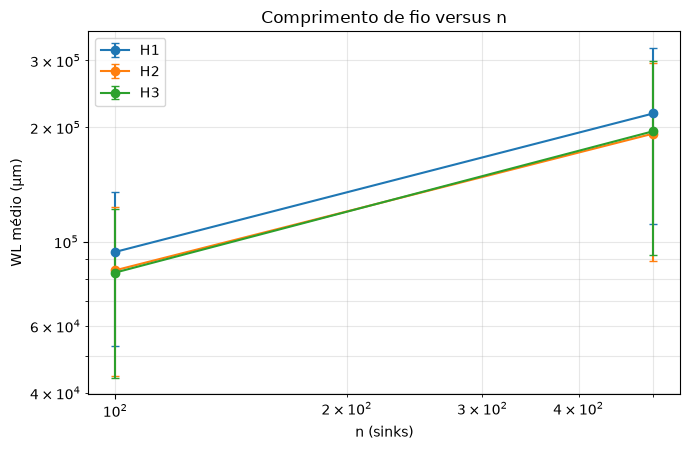

In [10]:
res3 = cts.testar_hipotese_3(df, fracao_minima=0.8, margem=0.01)
cts.imprimir_veredito("Hipótese 3", res3)
if res3["veredito"] is not None:
    print("Maior n testado:", res3["n_max_testado"])
    display(res3["tabela"])

    fig, ax = plt.subplots(figsize=(7, 4.6))
    cts.plotar_wl_vs_n(df, heuristicas=cts.HEURISTICAS_PROPOSTAS, ax=ax)
    plt.tight_layout()
    plt.show()

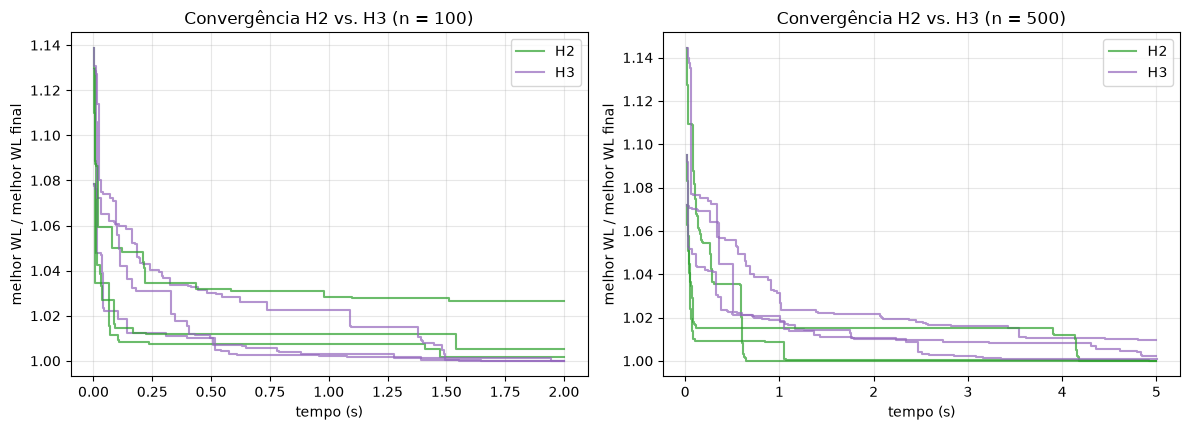

In [11]:
# Curvas de convergência (melhor WL até o instante t) de H2 e H3, 3 instâncias por tamanho
SEMENTE_CONV = int(df.loc[df["heuristica"] == "H2", "semente"].min())
tamanhos = sorted(df["n"].unique())
fig, axes = plt.subplots(1, len(tamanhos), figsize=(6 * len(tamanhos), 4.4), squeeze=False)
for ax, n in zip(axes[0], tamanhos):
    nomes = list(df.loc[df["n"] == n, "instancia"].unique()[:3])
    cts.plotar_convergencia_cts(historicos, nomes, semente=SEMENTE_CONV, ax=ax)
    ax.set_title(f"Convergência H2 vs. H3 (n = {n})")
plt.tight_layout()
plt.show()

## 8. Resumo dos vereditos

In [12]:
def _rotulo(v):
    return "PENDENTE" if v is None else ("CONFIRMADA" if v else "REFUTADA")

resumo = pd.DataFrame([
    dict(hipotese="H1: qualidade vs. controles (n ≤ 5000)", veredito=_rotulo(res1["veredito"]), observacao=res1.get("motivo", "")),
    dict(hipotese="H2: robustez a distribuições assimétricas", veredito=_rotulo(res2["veredito"]), observacao=res2.get("motivo", "")),
    dict(hipotese="H3: efeito da busca local e do ILS/SA", veredito=_rotulo(res3["veredito"]), observacao=res3.get("motivo", "")),
])
display(resumo)

,hipotese,veredito,observacao
0,H1: qualidade vs. controles (n ≤ 5000),PENDENTE,pendente: requer ≥ 2 controles implementados (...
1,H2: robustez a distribuições assimétricas,PENDENTE,pendente: C1 não implementada
2,H3: efeito da busca local e do ILS/SA,REFUTADA,


## Como completar a validação depois

1. **Controles:** implemente `heuristica_c1`, `heuristica_c2` e `heuristica_c3` em `cts_heuristicas.py` seguindo o contrato descrito acima das assinaturas (retornam `(arvore | None, HistoricoCTS)`). Não é preciso mudar o notebook: o runner e os testes passam a usá-las sozinhos.
2. **δ por instância:** `calibrar_delta` usa a C2 com δ = ∞ assim que ela existir. Apague o cache (`ARQUIVO_CACHE`) para recalibrar e rodar tudo com o mesmo δ.
3. **ISPD 2009/2010:** escreva um leitor que devolva `InstanciaCTS(nome, xy, cargas, raiz)` e passe a lista de instâncias a `executar_experimento` no lugar de `INSTANCIAS`. As hipóteses 1 e 3 usam n ≤ 5000 e todos os n; os benchmarks têm até 2249 sinks. Para a Hipótese 2, a coluna `distribuicao` do benchmark precisaria ser rotulada ou a hipótese avaliada só nas sintéticas.
4. **Protocolo completo:** troque `PRESET = "completo"` e use `N_PROCESSOS` > 1 se houver núcleos livres.